# Evaluating the Rwanda district rainfall dataset

Data: `data/processed/rwanda_rainfall_district_monthly.csv`, built by
`get_rwanda_rainfall.py` from WFP's CHIRPS district file on HDX (see `DATA_SOURCES.md`).

The evaluation has four parts. Each asks a different question:

1. **Structure.** Is the table complete, with no gaps, duplicates or missing values?
2. **Plausibility.** Are the values physically sensible, and are any months outliers?
3. **Internal consistency.** Do our monthly totals match WFP's own rolling totals,
   and do districts add up to their provinces?
4. **Climate and independent checks.** Does the data show Rwanda's known climate
   and known events, and does it agree with a separate dataset (NASA POWER)?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DIST = pd.read_csv("data/processed/rwanda_rainfall_district_monthly.csv")
PROV = pd.read_csv("data/processed/rwanda_rainfall_province_monthly.csv")
RAW = pd.read_csv("data/raw/rwa-rainfall-subnat-full.csv")
for df in (DIST, PROV):
    df["date"] = pd.to_datetime(df["month"])
RAW["date"] = pd.to_datetime(RAW["date"])

# Only use finished data for the evaluation. Preliminary months get revised.
dist = DIST[~DIST["preliminary"]].copy()
prov = PROV[~PROV["preliminary"]].copy()

# Chart styling: recessive grid and axes, thin marks, text in neutral ink
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "lines.linewidth": 2, "legend.frameon": False,
})
# Fixed categorical order: each province always gets the same colour
PROV_ORDER = ["Kigali City", "Southern Province", "Western Province",
              "Northern Province", "Eastern Province"]
PROV_COLOR = dict(zip(PROV_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
BLUE, RED = "#2a78d6", "#e34948"
print(f"{len(DIST):,} district rows; {len(dist):,} after dropping preliminary months")

16,470 district rows; 16,440 after dropping preliminary months


## 1. Structure

Every district should have one row per month, with no gaps, duplicates or missing values.

In [2]:
months = pd.period_range(dist["month"].min(), dist["month"].max(), freq="M")
per_district = dist.groupby("district")["month"].nunique()
checks = {
    "districts": dist["district"].nunique(),
    "provinces": dist["province"].nunique(),
    "first month": dist["month"].min(),
    "last final month": dist["month"].max(),
    "months expected per district": len(months),
    "districts with every month": int((per_district == len(months)).sum()),
    "duplicate district-month rows": int(dist.duplicated(["district", "month"]).sum()),
    "missing values": int(dist.isna().sum().sum()),
    "incomplete months (<3 dekads)": int((~dist["complete"]).sum()),
}
pd.Series(checks, name="value").to_frame()

,value
districts,30
provinces,5
first month,1981-01
last final month,2026-08
months expected per district,548
districts with every month,30
duplicate district-month rows,0
missing values,0
incomplete months (<3 dekads),0


## 2. Plausibility

Rainfall can't be negative. Rwanda rarely gets more than about 400 mm in a month.
Outliers are flagged with a **z-score per district and calendar month**: how far a
value is from that district's usual rainfall for that month, in standard
deviations. A large |z| isn't automatically wrong. It's a month to check against
reports, such as floods or droughts.

In [3]:
print("Negative values:", int((dist["rain_mm"] < 0).sum()))
print("Range of monthly rainfall: %.1f to %.1f mm" % (dist["rain_mm"].min(), dist["rain_mm"].max()))

g = dist.groupby(["district", "month_num"])["rain_mm"]
dist["z"] = (dist["rain_mm"] - g.transform("mean")) / g.transform("std")
outliers = dist.loc[dist["z"].abs() > 3.5, ["district", "month", "rain_mm", "normal_mm", "pct_of_normal", "z"]]
print(f"Months with |z| > 3.5: {len(outliers)} of {len(dist):,} ({100*len(outliers)/len(dist):.2f}%)")
outliers.sort_values("z", ascending=False).round(1).head(15)

Negative values: 0
Range of monthly rainfall: 1.2 to 380.9 mm
Months with |z| > 3.5: 47 of 16,440 (0.29%)


,district,month,rain_mm,normal_mm,pct_of_normal,z
11506,Musanze,2024-11,380.9,170.4,223.5,4.8
10957,Gakenke,2024-11,330.4,140.4,235.3,4.7
8212,Nyabihu,2024-11,372.2,168.8,220.5,4.7
12055,Burera,2024-11,314.8,140.0,224.9,4.6
8761,Ngororero,2024-11,349.0,153.5,227.3,4.3
11878,Burera,2010-02,273.6,92.8,294.9,4.3
5467,Muhanga,2024-11,315.5,140.2,225.0,4.3
2722,Gisagara,2024-11,348.8,145.9,239.1,4.3
14520,Kayonza,2001-07,19.1,4.9,387.9,4.3
3820,Huye,2024-11,308.1,132.4,232.6,4.2


**What to look at.** Most extreme months are in the dry season (June–August), where a
little rain gives a huge percentage. Those are harmless. The cluster to verify is
**November 2024**, which is more than 4 standard deviations above normal across
many districts at once. A country-wide signal suggests a real event rather than a
pixel error, but check it against Meteo Rwanda or news reports before relying on it.
These months were recent when downloaded, so a later CHIRPS revision could also
change them.

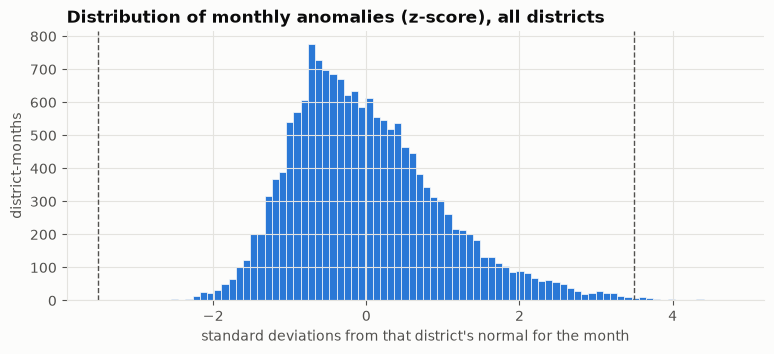

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(dist["z"].dropna(), bins=80, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
for x in (-3.5, 3.5):
    ax.axvline(x, color=INK2, linewidth=1, linestyle="--")
ax.set_title("Distribution of monthly anomalies (z-score), all districts")
ax.set_xlabel("standard deviations from that district's normal for the month")
ax.set_ylabel("district-months")
plt.show()

## 3. Internal consistency

**a. Our monthly totals against WFP's.** The raw file has `r1h`, WFP's own 1-month
rolling total. On the third dekad of each month (the 21st) it covers exactly that
month. If our summing is right, the two should match to rounding. Rusizi is left
out because its raw rows are split into two polygons, which we merged.

In [5]:
r1 = RAW[(RAW["adm_level"] == 2) & (RAW["date"].dt.day == 21) & (RAW["PCODE"] != "RW36")
         & (RAW["version"] == "final")].copy()
r1["month"] = r1["date"].dt.strftime("%Y-%m")
cmp = r1.merge(dist, left_on=["PCODE", "month"], right_on=["district_pcode", "month"])
diff = (cmp["rain_mm"] - cmp["r1h"]).abs()
print(f"Compared {len(cmp):,} district-months")
print(f"Max abs difference: {diff.max():.2f} mm; share within 0.5 mm: {(diff <= 0.5).mean():.1%}")

Compared 15,892 district-months
Max abs difference: 0.05 mm; share within 0.5 mm: 100.0%


**b. Districts against provinces.** WFP computed provinces separately. A
pixel-weighted average of each province's districts should reproduce the province
value. A small mismatch would be expected if border pixels were counted differently.
A large one would mean districts were assigned to the wrong province.

In [6]:
w = dist.assign(w=dist["rain_mm"] * dist["n_pixels"]).groupby(["province", "month"])
rebuilt = (w["w"].sum() / w["n_pixels"].sum()).rename("from_districts").reset_index()
pc = rebuilt.merge(prov[["province", "month", "rain_mm"]], on=["province", "month"])
pc["diff"] = pc["from_districts"] - pc["rain_mm"]
summary = pc.groupby("province").agg(
    corr=("diff", lambda s: np.corrcoef(pc.loc[s.index, "from_districts"], pc.loc[s.index, "rain_mm"])[0, 1]),
    mean_diff_mm=("diff", "mean"), mean_abs_diff_mm=("diff", lambda s: s.abs().mean()))
summary.round(3)

,corr,mean_diff_mm,mean_abs_diff_mm
province,,,
Eastern Province,1.0,0.000,0.026
Kigali City,1.0,0.002,0.030
Northern Province,1.0,-0.000,0.027
Southern Province,1.0,0.001,0.025
Western Province,1.0,0.001,0.027


## 4. Climate and independent checks

### Seasonal cycle

Rwanda has two rainy seasons, March–May (long rains) and September–December
(short rains), with a dry June–August. The east should be driest, the west wettest.

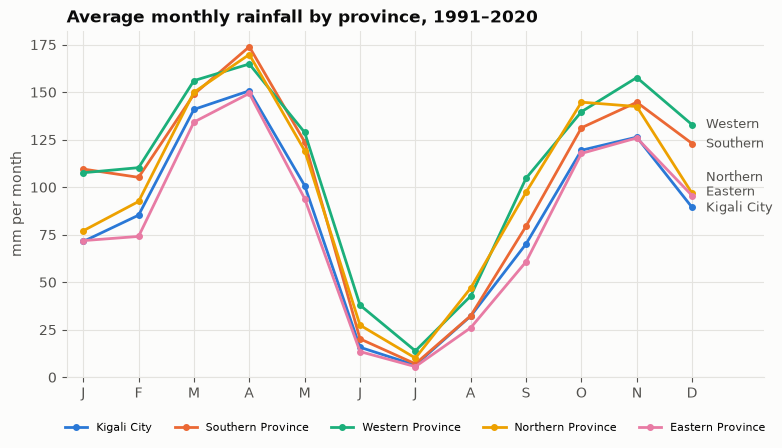

In [7]:
clim = prov[prov["year"].between(1991, 2020)].groupby(["province", "month_num"])["rain_mm"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 4.5))
for p in PROV_ORDER:
    ax.plot(clim.index, clim[p], color=PROV_COLOR[p], label=p, marker="o", markersize=4)
# Direct labels at December, pushed apart so they don't overlap
label_y, prev = {}, -1e9
for p in clim.loc[12].sort_values().index:
    prev = max(clim.loc[12, p], prev + 8)
    label_y[p] = prev
for p, y in label_y.items():
    ax.annotate(p.replace(" Province", ""), (12, clim.loc[12, p]), xytext=(12.25, y),
                textcoords="data", va="center", color=INK2, fontsize=9)
ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_xlim(0.7, 13.3)
ax.set_ylim(0, None)
ax.set_ylabel("mm per month")
ax.set_title("Average monthly rainfall by province, 1991–2020")
ax.legend(loc="upper center", ncol=5, fontsize=8, bbox_to_anchor=(0.5, -0.1))
plt.show()

### Average annual rainfall by district

Sorted from driest to wettest and coloured by province, so you can see the east–west gradient.

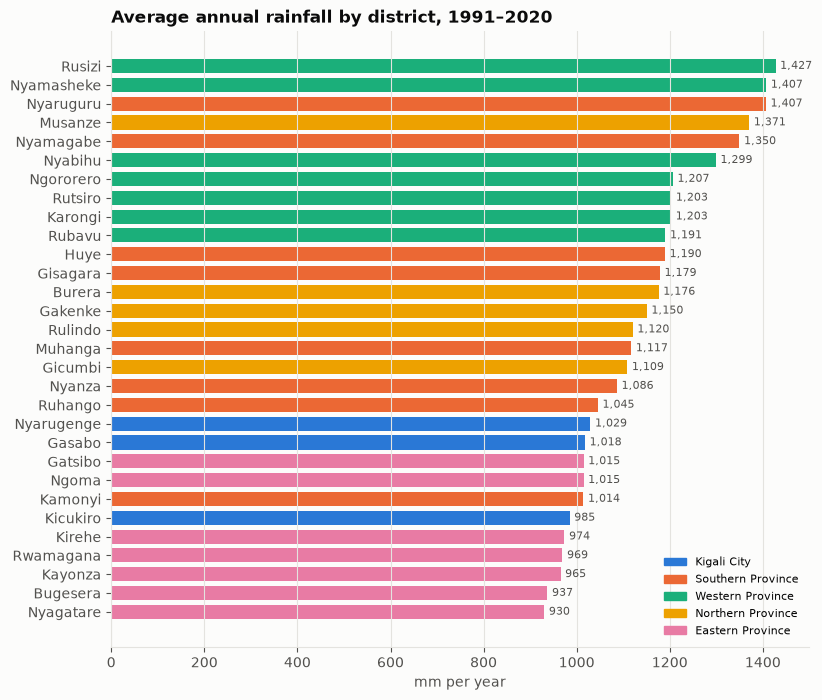

In [8]:
ann = (dist[dist["year"].between(1991, 2020)].groupby(["district", "province", "year"])["rain_mm"].sum()
       .groupby(["district", "province"]).mean().reset_index().sort_values("rain_mm"))
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(ann["district"], ann["rain_mm"], color=ann["province"].map(PROV_COLOR), height=0.75)
for y, v in enumerate(ann["rain_mm"]):
    ax.text(v + 10, y, f"{v:,.0f}", va="center", fontsize=8, color=INK2)
ax.set_xlabel("mm per year")
ax.grid(axis="y", visible=False)
ax.set_title("Average annual rainfall by district, 1991–2020")
handles = [plt.Rectangle((0, 0), 1, 1, color=PROV_COLOR[p]) for p in PROV_ORDER]
ax.legend(handles, PROV_ORDER, loc="lower right", fontsize=8)
plt.show()

### Wet and dry years by district

Each cell is a district's annual rainfall as a percentage of its 1989–2018 normal.
Blue is wetter than normal, red drier. Look for known events, such as the very wet
1997 short rains (El Niño), dry spells in the east around 2016, and heavy rain in
2023. Whole columns of one colour mean a country-wide signal. Isolated cells in an
otherwise normal year are worth checking.

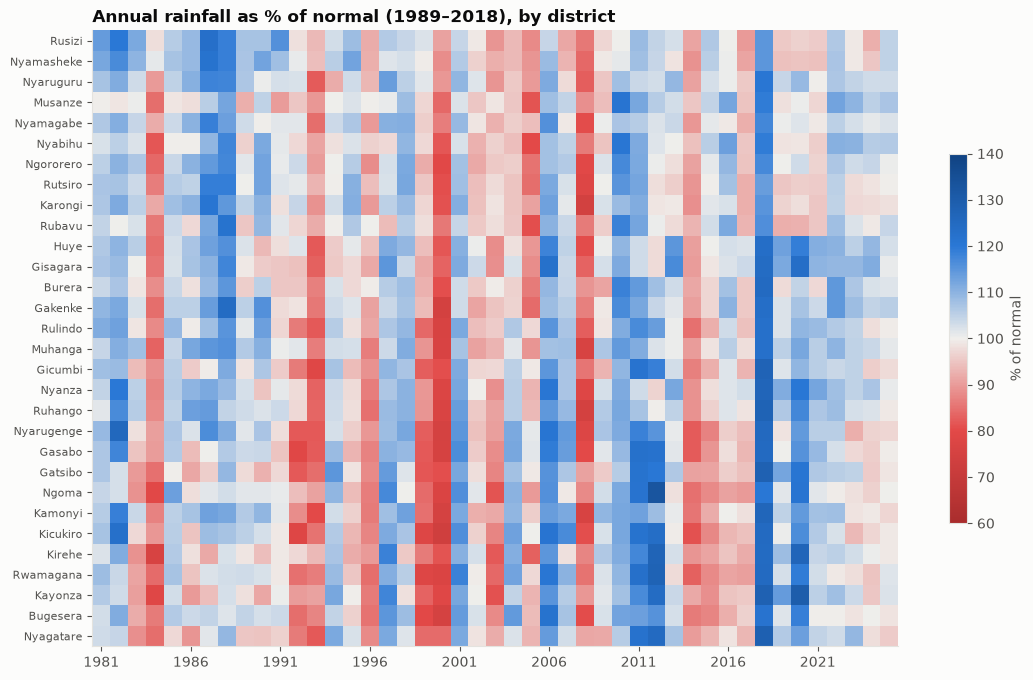

In [9]:
full_years = dist.groupby("year")["month"].nunique().loc[lambda s: s == 12].index
yr = dist[dist["year"].isin(full_years)].groupby(["district", "year"])[["rain_mm", "normal_mm"]].sum()
pct = (100 * yr["rain_mm"] / yr["normal_mm"]).unstack("year")
order = ann.set_index("district").index  # same order as the bar chart (dry -> wet)
pct = pct.loc[order[::-1]]

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap = LinearSegmentedColormap.from_list("div", ["#a92d2d", RED, "#f0efec", BLUE, "#104281"])
fig, ax = plt.subplots(figsize=(13, 8))
im = ax.imshow(pct.values, cmap=cmap, norm=TwoSlopeNorm(100, 60, 140), aspect="auto")
ax.set_yticks(range(len(pct)), pct.index, fontsize=8)
ax.set_xticks(range(0, pct.shape[1], 5), pct.columns[::5])
ax.grid(False)
ax.set_title("Annual rainfall as % of normal (1989–2018), by district")
fig.colorbar(im, ax=ax, shrink=0.6, label="% of normal")
plt.show()

### Comparison with an independent dataset: NASA POWER

CHIRPS shouldn't only be checked against itself. [NASA POWER](https://power.larc.nasa.gov/)
gives monthly precipitation for any point (`PRECTOTCORR`, from the MERRA-2
reanalysis with satellite corrections). It's built differently from CHIRPS, so
agreement is meaningful evidence.

The comparison is rough: a single point (an approximate town location) against a
whole-district average. Expect high correlation of the monthly pattern, not
identical totals. POWER's grid is coarse (0.5° × 0.625°, about 55 × 70 km), so
nearby towns can fall in the same cell. Musanze and Rubavu do, and get identical
NASA values. Results are cached in `data/raw/nasa_power/` so the API is
called only once.

In [10]:
import json
import requests

# Approximate coordinates of one town per province, and the district it sits in
POINTS = {
    "Gasabo":    ("Kigali", -1.95, 30.06),
    "Huye":      ("Huye (Butare)", -2.60, 29.74),
    "Musanze":   ("Musanze (Ruhengeri)", -1.50, 29.63),
    "Rubavu":    ("Rubavu (Gisenyi)", -1.68, 29.26),
    "Nyagatare": ("Nyagatare", -1.30, 30.33),
}
CACHE = Path("data/raw/nasa_power")
CACHE.mkdir(parents=True, exist_ok=True)

def nasa_power(lat, lon):
    path = CACHE / f"power_{lat}_{lon}.json"
    if not path.exists():
        url = ("https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=PRECTOTCORR"
               f"&community=AG&latitude={lat}&longitude={lon}&start=1981&end=2024&format=JSON")
        r = requests.get(url, timeout=180)
        r.raise_for_status()
        path.write_text(r.text)
    values = json.loads(path.read_text())["properties"]["parameter"]["PRECTOTCORR"]
    s = pd.Series(values)
    s = s[~s.index.str.endswith("13")]          # key YYYY13 is the annual value
    days = pd.to_datetime(s.index, format="%Y%m").days_in_month
    return pd.Series(s.values * days, index=s.index.str[:4] + "-" + s.index.str[4:])  # mm/day -> mm

rows, series = [], {}
for district, (town, lat, lon) in POINTS.items():
    try:
        nasa = nasa_power(lat, lon)
    except Exception as e:
        print(f"Skipping {town}: {e}")
        continue
    chirps = dist[dist["district"] == district].set_index("month")["rain_mm"]
    both = pd.concat({"chirps": chirps, "nasa": nasa}, axis=1).dropna()
    both = both[both["nasa"] >= 0]                # POWER uses -999 for missing
    series[district] = both
    rows.append({"district": district, "point": town, "months": len(both),
                 "corr (monthly)": both.corr().iloc[0, 1],
                 "CHIRPS mm/yr": both["chirps"].mean() * 12,
                 "NASA POWER mm/yr": both["nasa"].mean() * 12})
pd.DataFrame(rows).set_index("district").round(2)

,point,months,corr (monthly),CHIRPS mm/yr,NASA POWER mm/yr
district,,,,,
Gasabo,Kigali,528,0.73,1023.44,1167.93
Huye,Huye (Butare),528,0.71,1205.36,1187.26
Musanze,Musanze (Ruhengeri),528,0.66,1376.90,1561.76
Rubavu,Rubavu (Gisenyi),528,0.65,1202.74,1561.76
Nyagatare,Nyagatare,528,0.73,923.97,1072.01


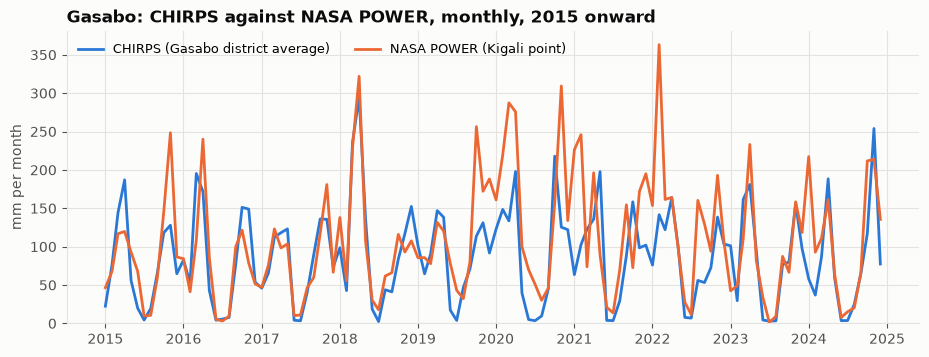

In [11]:
if series:
    d = "Gasabo" if "Gasabo" in series else next(iter(series))
    b = series[d].loc["2015-01":]
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(pd.to_datetime(b.index), b["chirps"], color=BLUE, label=f"CHIRPS ({d} district average)")
    ax.plot(pd.to_datetime(b.index), b["nasa"], color="#eb6834", label=f"NASA POWER ({POINTS[d][0]} point)")
    ax.set_ylabel("mm per month")
    ax.set_ylim(0, None)
    ax.set_title(f"{d}: CHIRPS against NASA POWER, monthly, 2015 onward")
    ax.legend(loc="upper left", ncol=2, fontsize=9)
    plt.show()

## How to read the results

| Check | Good sign | Warning sign |
|---|---|---|
| Structure | 30 districts × every month, 0 missing, 0 duplicates | Gaps or duplicates (re-run the download) |
| Plausibility | No negatives. Under ~1% of months with \|z\| > 3.5 | Many extreme months in one district (pixel or boundary issue) |
| WFP `r1h` match | Differences of a fraction of a mm | Large differences (an error in summing) |
| District vs province | Correlation ≈ 1, mean difference a few mm | Systematic offset in one province |
| Seasonal cycle | Two rainy seasons, dry Jun–Aug, east driest | Wrong timing or ordering |
| NASA POWER | Monthly correlation around 0.7 or higher | Low correlation for one district only |

Limits of this evaluation: there is no comparison with Rwanda's own rain gauges
(Meteo Rwanda). That is the strongest test and needs station data requested from
Meteo Rwanda. Also, for small districts such as Nyarugenge (2 CHIRPS pixels),
values are less reliable than these averages suggest.